# 文本 01｜把“文字进入网络”拆成看得见的几步

上一页已经得到预测；这一页暂时不训练，用颜色、位置和很小的数值弄清输入。读完应能解释：字符编号为何不能直接当情感大小、不同长度如何组成 batch、Embedding 查出了什么，以及怎样避开 PAD 读取句子表示。

按“先猜图上的位置 → 运行核对 → 只改一项 → 解释差异”进行。人工短句与小张量仅用于讲解；词表仍来自真实训练集。每张图下面的代码可独立重画，不需要重跑模型训练。

> **课堂预览**　本页的图是 2026-10-17 的本地 CPU 运行快照，重新执行会更新；人工图解与训练结果已分别标明。只阅读可直接展开输出，实验时仍需从第一格执行。真实评论原文的打印未嵌入快照；有本地课程数据时运行对应格查看。

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import torch
import matplotlib.pyplot as plt

# 支持从仓库根、03_rnn_lab、当前任务子目录启动，不依赖盘符或安装 rnn_lab。
LAB_DIR = next((candidate for base in (Path.cwd(), *Path.cwd().parents)
                for candidate in (base, base / "03_rnn_lab")
                if (candidate / "rnn_lab").is_dir()), None)
if LAB_DIR is None:
    raise FileNotFoundError("请从课程仓库、03_rnn_lab 或本任务目录启动 Notebook。")
if str(LAB_DIR) not in sys.path:
    sys.path.insert(0, str(LAB_DIR))
DATA_DIR = LAB_DIR / "06_text_classification" / "data"
torch.set_num_threads(1)
from rnn_lab import configure_chinese_font, seed_everything
configure_chinese_font()
from rnn_lab.text_data import (load_text_data, build_vocab, encode_text,
    make_text_dataloaders, text_data_diagnostics, save_text_preprocessing,
    load_text_preprocessing)
from rnn_lab.text_engine import (TextExperimentConfig, run_text_experiment,
    predict_text, evaluate_text_final, export_text_experiments_csv, save_text_run)
from rnn_lab.text_plots import (plot_text_history, plot_text_confusion,
    plot_text_comparison, plot_text_states, text_examples)
print("实验室：", LAB_DIR, "；CPU 线程：", torch.get_num_threads())

实验室： <实验室目录> ；CPU 线程： 1


In [2]:
data = load_text_data(DATA_DIR)
vocab = build_vocab(record["text"] for record in data.splits["train"])
MAX_LENGTH = 100  # 先预测：改成 40，哪些评论会截断，词表会跟着变吗？
assert vocab["<PAD>"] == 0 and vocab["<UNK>"] == 1
print("词表大小：", len(vocab), "；前 20 项：", list(vocab.items())[:20])
real_review = data.splits["train"][0]["text"]
encoded = encode_text(real_review, vocab, MAX_LENGTH)
print("真实训练原文：", real_review)
print("清理后字符：", list(encoded["cleaned_text"])[:MAX_LENGTH])
print("编码：", encoded)
print("PAD不是文本字符；UNK代表训练词表没见过的字符。")

## 第一步：字符排成一列，词表给每个字符一个编号

先读上行字符，再读对应的下行整数。编号只是词表地址：编号更大的字不代表更正面；同一个字在不同句子中使用相同编号。没在训练词表见过的字变为 UNK，不会临时扩充词表。

下面是人工例句，`TOKEN_LIMIT` 可以改小。**预测：**若从 12 改成 6，哪些字会消失？再看图上的原长、有效长与截断标记。

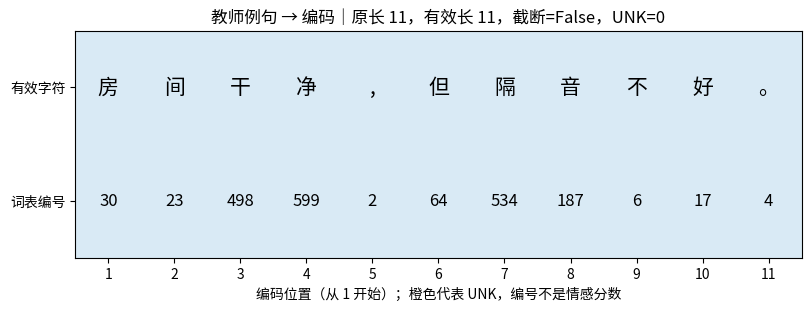

In [3]:
from rnn_lab.teaching_visuals import plot_token_encoding
import matplotlib.pyplot as plt

TOKEN_SENTENCE = "房间干净，但隔音不好。"
TOKEN_LIMIT = 12
fig = plot_token_encoding(vocab, TOKEN_SENTENCE, max_length=TOKEN_LIMIT)
plt.show()
plt.close(fig)

## 三条真实评论组成一个批次

`token_ids:[B,T]` 与 `labels:[B]` 都是 int64；`lengths:[B]` 是截断后的真实有效长度。T 是当前批次补齐后的长度，通常不等于 `max_length`；PAD 只补在右侧，不算真实文本。

先预测最短句的最后一个有效字符在哪个索引，再查看实际 `lengths`。改变 `BATCH_SIZE` 后，T 为什么也可能变化？

In [4]:
BATCH_SIZE = 3
loaders = make_text_dataloaders(data, vocab, max_length=MAX_LENGTH,
                              batch_size=BATCH_SIZE, seed=42)
batch = next(iter(loaders["val"]))
for name in ("token_ids", "lengths", "labels"):
    print(name, tuple(batch[name].shape), batch[name].dtype)
print("真实长度：", batch["lengths"].tolist())
for row, text, length in zip(batch["token_ids"], batch["texts"], batch["lengths"]):
    n = int(length)
    print("\n原文：", text[:140])
    print("有效ID：", row[:n].tolist())
    print("有效句尾索引：", n - 1, "；右侧PAD个数：", int((row[n:] == 0).sum()))
assert batch["token_ids"].dtype == batch["labels"].dtype == torch.int64
assert batch["lengths"].dtype == torch.int64

## 第二步：把长短不同的句子放进同一个矩形

上面的真实 batch 用来核对实际 shape；下面换成人工短句，方便逐格看。每行是一条评论，每列是一个时间位置，灰色 PAD 把短句右侧补齐。绿色标记指向每条句子的有效结束边界，不一定在最右边。

`lengths` 记录每行有效长度，T 是当前 batch 的补齐宽度。**先预测：**把第一句延长，会改变其他句子的真实长度吗？会改变矩形宽度吗？`padding_idx=0` 只控制 Embedding 的 PAD 行；循环层仍可能在 PAD 位置继续更新状态。

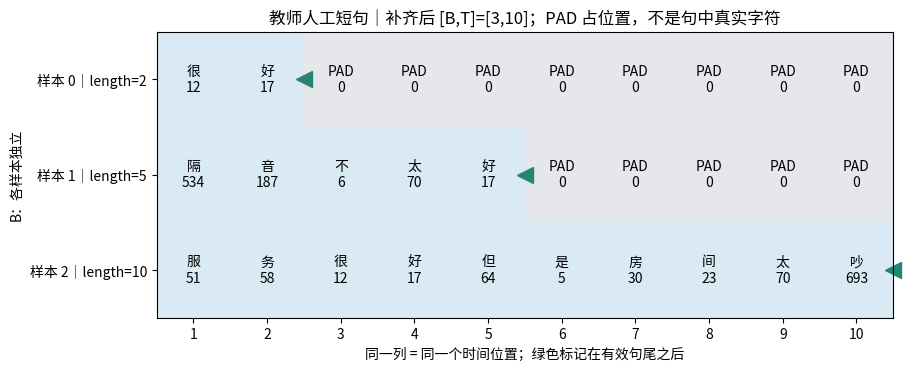

In [5]:
from rnn_lab.teaching_visuals import plot_padding_demo
import matplotlib.pyplot as plt

DEMO_SENTENCES = ["很好", "隔音不太好", "服务很好但是房间太吵"]
fig = plot_padding_demo(vocab, DEMO_SENTENCES, max_length=12)
plt.show()
plt.close(fig)

## Embedding 是查表，ID、E、H 是不同概念

同一个 ID 在同一张表中查到同一个 E 维向量。ID 是离散编号，没有“ID大两倍就语义大两倍”的意义。E 是这张可训练表每一行的宽度，H 由后续循环层设置；词表大小是表的行数。

这里只观察随机初始化的表，没有学过情感。`padding_idx=0` 使 PAD 的 Embedding 保持零，但**不意味着循环层自动跳过 PAD**。状态依旧会经过循环权重和偏置更新。

In [6]:
EMBEDDING_DIM = 6  # 改为 10，先预测 token_ids 的 shape 是否改变。
seed_everything(42)
embedding = torch.nn.Embedding(len(vocab), EMBEDDING_DIM, padding_idx=0)
with torch.no_grad():
    embedded = embedding(batch["token_ids"])
print("查表权重 [词表大小,E]：", tuple(embedding.weight.shape))
print("输入ID [B,T]：", tuple(batch["token_ids"].shape))
print("查表后 [B,T,E]：", tuple(embedded.shape))
print("PAD对应向量：", embedding.weight[0].detach().tolist())
print("首条首字符ID及向量：", int(batch["token_ids"][0, 0]), embedded[0, 0].tolist())
assert torch.equal(embedding.weight[0].detach(), torch.zeros(EMBEDDING_DIM))

查表权重 [词表大小,E]： (3081, 6)
输入ID [B,T]： (3, 100)
查表后 [B,T,E]： (3, 100, 6)
PAD对应向量： [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
首条首字符ID及向量： 93 [-0.9769555926322937, -0.03363388776779175, 1.8594977855682373, 2.6221468448638916, 0.36905255913734436, 0.3802972435951233]


## 第三步：编号是地址，Embedding 是这个地址里的一组数

图里每行是一次查表，每列是向量的一个坐标。两个“好”在不同位置，但查同一个表，所以取出的向量完全相同。**上下文差异要由后面的循环网络处理。**

这张表刚刚随机初始化，尚未学到情感；红色表示数值为正，蓝色表示为负，不表示正面或负面。试着改变 `EMBEDDING_DIM`，重新运行上面的初始化格，观察图宽与 `[B,T,E]` 的 E。

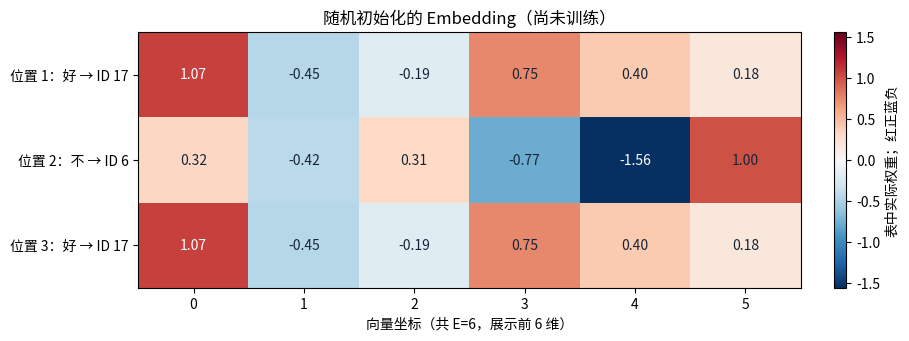

In [7]:
from rnn_lab.teaching_visuals import plot_embedding_vectors
import matplotlib.pyplot as plt

fig = plot_embedding_vectors(embedding, vocab, "好不好")
plt.show()
plt.close(fig)

## 可手算的人工状态例子：三种读取位置

这是**教师指定的状态数值**，不是训练模型的输出，也不是正式数据。第一句有效长度2，第二句有效长度4；第一句后两步在处理 PAD 时状态变成 `[9,9]`。

先手算第一句的有效句尾、物理末尾、有效平均和包含 PAD 的平均，再运行核对。这里按样本写出切片方便理解；作业要自己推广到任意 B/T/H 的批次，不写死这些数字。

In [8]:
# [B=2,T=4,H=2]；后两行9表示人为指定的PAD时刻状态。
toy_hidden = torch.tensor([[[1., 2.], [3., 4.], [9., 9.], [9., 9.]],
                           [[2., 1.], [4., 3.], [6., 5.], [8., 7.]]])
print("第一句有效句尾：", toy_hidden[0, 1].tolist())
print("第一句错误物理末尾：", toy_hidden[0, -1].tolist())
print("第一句排除PAD的平均：", toy_hidden[0, :2].mean(dim=0).tolist())
print("第一句错误全长平均：", toy_hidden[0].mean(dim=0).tolist())
print("第二句有效句尾：", toy_hidden[1, 3].tolist())
print("第二句没有PAD，其有效平均：", toy_hidden[1, :4].mean(dim=0).tolist())
# 平均循环隐藏状态，与直接平均Embedding，是不同模型表示。

第一句有效句尾： [3.0, 4.0]
第一句错误物理末尾： [9.0, 9.0]
第一句排除PAD的平均： [2.0, 3.0]
第一句错误全长平均： [5.5, 6.0]
第二句有效句尾： [8.0, 7.0]
第二句没有PAD，其有效平均： [5.0, 4.0]


## 第四步：句尾不等于矩形最右边

图中使用上格的人工隐藏状态，方便手算，不是训练后的隐藏向量。样本 0 只有前两步有效，后面故意放入 9；样本 1 四步都有效。

先遮住右侧表格：样本 0 的有效 last 应取哪一列？平均前两列与平均全部四列各得到什么？运行后对照。样本 1 的两种写法可能碰巧一样，因此**只用等长样本不能验证变长读出是否正确**。

本任务的损失对应整条评论的标签，不是给每个字符都分配一个正负标签。

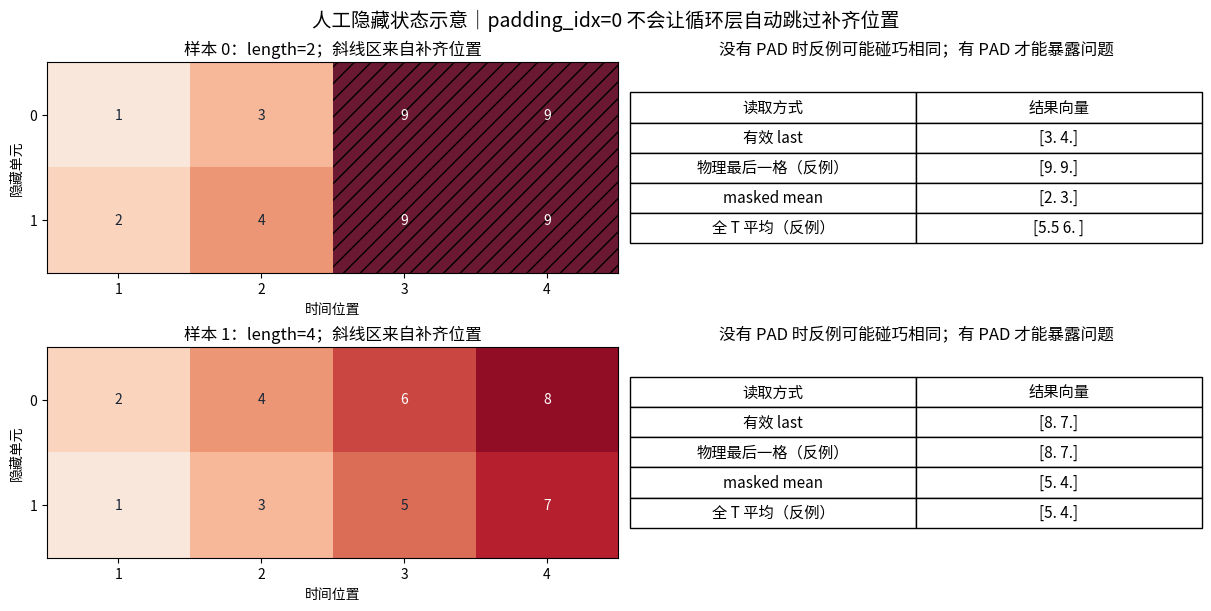

In [9]:
from rnn_lab.teaching_visuals import plot_readout_demo
import matplotlib.pyplot as plt

fig = plot_readout_demo(toy_hidden, torch.tensor([2, 4]))
plt.show()
plt.close(fig)

## 边界：空、未见字符和过长输入

下列为**人工输入，仅做编码观察**。空文本清理后使用一个 UNK 占位，length=1 并标记 empty；全 UNK 也有明确提示。超长文本截断到 `max_length`，length 对应截断后的长度；未知字符不会加入词表。观察后解释：为何不能让空句长度变成0后再取 `length-1`？

In [10]:
vocab_before = dict(vocab)
unseen = next(chr(point) for point in range(0xE000, 0xF8FF) if chr(point) not in vocab)
for text in ["", "   ", unseen, "好" * (MAX_LENGTH + 7), "不"]:
    info = encode_text(text, vocab, MAX_LENGTH)
    print(repr(text[:30]), info)
assert vocab == vocab_before, "验证/用户输入编码不能扩展训练词表。"

'' {'token_ids': [1], 'length': 1, 'cleaned_text': '', 'characters': ['<UNK>'], 'truncated': False, 'unknown_count': 1, 'empty': True, 'original_length': 0}
'   ' {'token_ids': [1], 'length': 1, 'cleaned_text': '', 'characters': ['<UNK>'], 'truncated': False, 'unknown_count': 1, 'empty': True, 'original_length': 0}
'\ue000' {'token_ids': [1], 'length': 1, 'cleaned_text': '\ue000', 'characters': ['\ue000'], 'truncated': False, 'unknown_count': 1, 'empty': False, 'original_length': 1}
'好好好好好好好好好好好好好好好好好好好好好好好好好好好好好好' {'token_ids': [17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17], 'length': 100, 'cleaned_text': '好好好好好好好好好好好好好好好好好好好好好好好好好好好好好好好

### 把四张图连起来检查一次

对一个自己输入的句子，依次说清：哪些字符保留 → 哪些变成 UNK → batch 补了几格 PAD → 查表后的 E 是多少 → 有效句尾在哪里。空白输入的单 UNK 是让接口能够处理边界的哨兵，不能因此把空白预测当有效情感分析。

课堂两分钟练习：画一个含两条不同长度短句的 B×T 矩形，标出有效末尾。交换两句话只改变 batch 行次序；交换同一句的两个字则改变序列次序。这两种操作对模型含义不同。

**记录区：**我的预测……；我只改了 BATCH_SIZE / MAX_LENGTH / EMBEDDING_DIM 中的一项……；观察到的 B/T/E 变化……；有效句尾与物理末尾的区别……。下一页比较完整模型，但仍只用验证集选型。

## 保存与结束

本页输出写入带运行标识的新目录，保留旧记录。先保存 Notebook，再按需运行下一格关闭图片。本页不自动关闭内核；不要为了重新看图反复训练。共享服务器每次只运行一个训练任务。

In [11]:
# 需要重新实验时建议重启内核，从头运行；本格仅关闭图片。
plt.close("all")